# 03 · Feature Engineering
**UTS Data Science – Kelas RPL (DASI) · Daniel Haganta Ginting (41426090)**

| | |
|---|---|
| **Input** | `../data/processed/01_clean.csv`, `../data/processed/01_cuaca_harian.csv` |
| **Output** | `../data/processed/03_train_fe.csv`, `03_test_fe.csv`, `03_kamus_fitur.csv`, `03_ringkasan.json` |
| **Prinsip** | Semua fitur hanya memakai informasi **sampai H-1** (hari kerja sebelumnya), sehingga bisa dipakai untuk memprediksi harga hari ini. Encoding berbasis target, binning berbasis kuantil, transformasi, dan scaling **di-fit hanya pada data latih** setelah split. |

Alur: (1) fitur baru → (2) split latih/uji berbasis waktu → (3) encoding → (4) diskretisasi berbasis kuantil → (5)
transformasi → (6) scaling → (7) bukti kegunaan fitur → simpan.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

PROC = Path("../data/processed")
FIG = Path("../laporan/figures")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10})
from matplotlib.ticker import FuncFormatter
RIBUAN = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))   # sumbu harga: 100000 -> 100.000

PASAR = ["Produsen", "Pedagang Besar", "Pasar Tradisional", "Pasar Modern"]
TARGET = "Harga_Cabai_Merah_Keriting"
df = pd.read_csv(PROC / "01_clean.csv", parse_dates=["Tanggal"]).sort_values(["Kategori_Pasar", "Tanggal"]).reset_index(drop=True)
cuaca = pd.read_csv(PROC / "01_cuaca_harian.csv", parse_dates=["Tanggal"]).set_index("Tanggal").asfreq("D")
print("Data bersih:", df.shape, "| cuaca harian:", cuaca.shape, cuaca.index.min().date(), "s.d.", cuaca.index.max().date())
kamus = []   # SATU entri per kolom fitur: nama | jenis | rumus | makna bisnis
def catat(nama, jenis, rumus, makna):
    kamus.append({"fitur": nama, "jenis": jenis, "rumus": rumus, "makna": makna})

Data bersih: (6352, 10) | cuaca harian: (2402, 4) 2019-07-04 s.d. 2026-01-29


## 1 · Membuat fitur baru
Fitur dibuat dari **7 jenis**: waktu, lag/agregasi per kelompok (per pasar), rasio/selisih, antar-kelompok (pasar hulu),
domain cuaca, flag/biner hari besar & musim, dan interaksi. Diskretisasi dibuat di bagian 4.

In [2]:
# (a) Fitur WAKTU
df["Bulan"] = df["Tanggal"].dt.month
df["Hari_dalam_Minggu"] = df["Tanggal"].dt.dayofweek            # 0 = Senin ... 4 = Jumat
df["Bulan_sin"] = np.sin(2 * np.pi * df["Bulan"] / 12)
df["Bulan_cos"] = np.cos(2 * np.pi * df["Bulan"] / 12)
catat("Bulan", "Waktu", "Tanggal.month (1-12)", "Menangkap musim panen (Jun termurah) dan paceklik (Feb termahal) hasil EDA")
catat("Hari_dalam_Minggu", "Waktu", "Tanggal.dayofweek (0=Senin..4=Jumat)", "Pola harian pasokan/belanja dalam seminggu")
catat("Bulan_sin", "Waktu (siklik)", "sin(2*pi*Bulan/12)", "Desember dan Januari berdekatan secara musim; angka 12 dan 1 tidak")
catat("Bulan_cos", "Waktu (siklik)", "cos(2*pi*Bulan/12)", "Pasangan Bulan_sin agar setiap bulan punya koordinat unik di lingkaran")

# (b) LAG & AGREGASI PER KELOMPOK (per Kategori_Pasar) - semua digeser 1 hari kerja agar tidak memakai harga hari ini
g = df.groupby("Kategori_Pasar")[TARGET]
df["Harga_Lag1"] = g.shift(1)
df["Harga_Lag5"] = g.shift(5)
df["Harga_Lag20"] = g.shift(20)
df["Harga_MA7"] = g.transform(lambda s: s.shift(1).rolling(7).mean())
df["Harga_MA20"] = g.transform(lambda s: s.shift(1).rolling(20).mean())
df["Harga_Std7"] = g.transform(lambda s: s.shift(1).rolling(7).std())
catat("Harga_Lag1", "Lag per kelompok", "harga pasar yg sama pada hari kerja t-1", "Harga kemarin = acuan utama pedagang (price rigidity)")
catat("Harga_Lag5", "Lag per kelompok", "harga t-5 (seminggu lalu)", "Posisi harga seminggu sebelumnya")
catat("Harga_Lag20", "Lag per kelompok", "harga t-20 (sebulan lalu)", "Posisi harga sebulan sebelumnya (autokorelasi 0,56 di EDA)")
catat("Harga_MA7", "Agregasi per kelompok", "mean(harga t-7..t-1) per pasar", "Tren mingguan yang meredam fluktuasi harian")
catat("Harga_MA20", "Agregasi per kelompok", "mean(harga t-20..t-1) per pasar", "Tren bulanan")
catat("Harga_Std7", "Agregasi per kelompok", "std(harga t-7..t-1) per pasar", "Volatilitas jangka pendek: pasar sedang bergejolak atau tenang")

# (c) RASIO / SELISIH
df["Momentum_5H"] = df["Harga_Lag1"] / g.shift(6) - 1
df["Deviasi_MA20"] = df["Harga_Lag1"] / df["Harga_MA20"] - 1
catat("Momentum_5H", "Rasio", "harga t-1 / harga t-6 - 1", "Arah & kecepatan perubahan 5 hari terakhir (sedang naik/turun)")
catat("Deviasi_MA20", "Rasio", "harga t-1 / MA20 - 1", "Seberapa jauh harga kemarin di atas/bawah tren bulanan (potensi koreksi)")

# (d) ANTAR-KELOMPOK: harga pasar hulu kemarin (sama untuk ke-4 pasar pada tanggal yang sama)
wide = df.pivot(index="Tanggal", columns="Kategori_Pasar", values=TARGET)
hulu = wide[["Produsen", "Pedagang Besar"]].shift(1).rename(columns={"Produsen": "Harga_Produsen_Lag1", "Pedagang Besar": "Harga_PB_Lag1"})
df = df.merge(hulu, left_on="Tanggal", right_index=True, how="left")
df["Rasio_Thd_Grosir_Lag1"] = df["Harga_Lag1"] / df["Harga_PB_Lag1"]
catat("Harga_Produsen_Lag1", "Antar-kelompok", "harga Produsen t-1", "Harga di tingkat petani sebagai sinyal hulu")
catat("Harga_PB_Lag1", "Antar-kelompok", "harga Pedagang Besar t-1", "Harga grosir = modal pedagang eceran (Spearman 0,89 dgn Pasar Tradisional di EDA)")
catat("Rasio_Thd_Grosir_Lag1", "Rasio", "harga pasar t-1 / harga Pedagang Besar t-1", "Markup terhadap grosir; EDA: rasio Trad/Grosir bergerak 0,99-1,55")
print(df.shape)

(6352, 25)


**Apa:** 4 fitur waktu, 6 fitur lag/agregasi per pasar, 3 fitur rasio, dan 2 fitur antar-kelompok (harga hulu kemarin).

**Mengapa:** EDA menunjukkan autokorelasi lag-1 sebesar 0,961, sehingga harga kemarin adalah informasi terkuat. Harga eceran
mengikuti grosir (rho 0,89), dan ada pola musiman bulanan. Semua fitur harga **digeser minimal 1 hari kerja** (`shift(1)`
per `Kategori_Pasar`), sehingga tidak ada fitur yang memakai harga hari ini. Lag dihitung per pasar agar harga Produsen
tidak tercampur dengan harga Pasar Modern.

**Arti:** `Bulan_sin/cos` membuat Desember (12) dan Januari (1) berdekatan. `Momentum_5H` dan `Deviasi_MA20` memberi informasi
*arah* harga, bukan hanya level. Contohnya, Deviasi_MA20 = +0,10 berarti harga kemarin 10% di atas rata-rata 20 hari.

**Pengaruh:** menghasilkan 15 kolom baru (25 kolom total). Baris awal tanpa riwayat menjadi NaN dan ditangani di bawah.

In [3]:
# (e) DOMAIN CUACA - dihitung dari hari KALENDER (termasuk Sabtu-Minggu) lalu diambil s.d. H-1
hujan = cuaca["Curah_Hujan_mm"]
cal = pd.DataFrame(index=cuaca.index)
cal["Hujan_Lag1"] = hujan.shift(1)
cal["Akumulasi_Hujan_7H"] = hujan.shift(1).rolling(7).sum()
cal["Akumulasi_Hujan_30H"] = hujan.shift(1).rolling(30).sum()
cal["Akumulasi_Hujan_60H_Lag11Mgg"] = hujan.rolling(60).sum().shift(77)
cal["Hari_Hujan_Lebat_30H"] = (hujan >= 20).astype(int).shift(1).rolling(30).sum()
cal["Suhu_Lag1"] = cuaca["Suhu_Rata2_C"].shift(1)
cal["Angin_Lag1"] = cuaca["Kecepatan_Angin_Maks_kmh"].shift(1)
URUT_CUACA = {1: 0, 2: 0, 3: 0, 51: 1, 53: 1, 55: 1, 61: 2, 63: 3, 65: 4}   # Berawan < Gerimis < Hujan Ringan < Sedang < Lebat
cal["Kategori_Cuaca_Lag1"] = cuaca["Kode_Cuaca_WMO"].map(URUT_CUACA).shift(1)
df = df.merge(cal, left_on="Tanggal", right_index=True, how="left")
catat("Hujan_Lag1", "Domain cuaca", "curah hujan H-1 (mm)", "Hujan kemarin mengganggu panen & pengiriman")
catat("Akumulasi_Hujan_7H", "Domain cuaca", "sum(hujan kalender t-7..t-1)", "Efek hujan mingguan pada distribusi")
catat("Akumulasi_Hujan_30H", "Domain cuaca", "sum(hujan kalender t-30..t-1)", "Kondisi lahan sebulan terakhir (risiko penyakit antraknosa/patek)")
catat("Akumulasi_Hujan_60H_Lag11Mgg", "Domain cuaca", "sum(hujan 60 hari) yang berakhir 77 hari sebelum t", "EDA: korelasi hujan-harga terkuat (rho 0,20) pada jeda ±11 minggu = siklus tanam-panen cabai")
catat("Hari_Hujan_Lebat_30H", "Domain cuaca", "jumlah hari hujan >= 20 mm dlm 30 hari terakhir", "Frekuensi hujan sedang-lebat (BMKG) yang merusak bunga/buah")
catat("Suhu_Lag1", "Domain cuaca", "suhu rata-rata H-1", "Suhu memengaruhi pematangan & pembusukan cabai")
catat("Angin_Lag1", "Domain cuaca", "angin maks H-1", "Angin kencang merontokkan bunga cabai")
catat("Kategori_Cuaca_Lag1", "Domain cuaca (ordinal)", "kode WMO H-1 -> 0 Berawan,1 Gerimis,2 Ringan,3 Sedang,4 Lebat", "Intensitas cuaca kemarin dalam skala berurutan")

# (f) FLAG / BINER + DOMAIN HARI BESAR (kalender libur resmi, paket holidays)
libur = holidays.country_holidays("ID", years=range(2019, 2028))
def tanggal_libur(nama):
    return sorted(pd.Timestamp(d) for d, n in libur.items() if nama in n.split("; "))
idul_fitri = tanggal_libur("Hari Raya Idul Fitri")
besar = sorted(set(idul_fitri + tanggal_libur("Hari Raya Idul Adha") + tanggal_libur("Hari Raya Natal")
                   + tanggal_libur("Tahun Baru Masehi") + tanggal_libur("Tahun Baru Imlek")))
def hari_menuju(t, daftar):
    nxt = [d for d in daftar if d >= t]
    return (nxt[0] - t).days if nxt else np.nan
df["Hari_Menuju_Idul_Fitri"] = df["Tanggal"].apply(lambda t: hari_menuju(t, idul_fitri))
df["Is_Ramadan"] = df["Hari_Menuju_Idul_Fitri"].between(1, 30).astype(int)
df["Is_Menjelang_Hari_Besar"] = df["Tanggal"].apply(lambda t: int(hari_menuju(t, besar) <= 7))
df["Is_Musim_Hujan"] = df["Bulan"].isin([9, 10, 11, 12]).astype(int)
catat("Hari_Menuju_Idul_Fitri", "Domain kalender", "selisih hari ke Idul Fitri berikutnya", "Jarak ke puncak permintaan tahunan")
catat("Is_Ramadan", "Flag", "1 jika 1-30 hari sebelum Idul Fitri", "Periode Ramadan (permintaan rumah tangga naik)")
catat("Is_Menjelang_Hari_Besar", "Flag", "1 jika <=7 hari sebelum Idul Fitri/Idul Adha/Natal/Tahun Baru/Imlek", "Lonjakan belanja menjelang hari raya")
catat("Is_Musim_Hujan", "Flag", "1 jika bulan Sep-Des", "EDA: hari 'mahal' 32,4% di Sep-Des vs 20,8% bulan lain (chi-square p<0,001)")

# (g) ORDINAL rantai pasok + INTERAKSI
df["Level_Rantai_Pasok"] = df["Kategori_Pasar"].map(dict(zip(PASAR, [1, 2, 3, 4])))
df["Interaksi_Lag1_x_MusimHujan"] = df["Harga_Lag1"] * df["Is_Musim_Hujan"]
catat("Level_Rantai_Pasok", "Encoding ordinal", "Produsen=1, Pedagang Besar=2, Pasar Tradisional=3, Pasar Modern=4", "Posisi di rantai distribusi (hulu->hilir), harga median naik tiap level")
catat("Interaksi_Lag1_x_MusimHujan", "Interaksi", "Harga_Lag1 x Is_Musim_Hujan", "Membolehkan kekuatan 'harga kemarin' berbeda saat musim hujan")
print("Shape setelah fitur baru:", df.shape)

Shape setelah fitur baru: (6352, 39)


**Apa:** 8 fitur domain cuaca, 4 fitur kalender/flag, 1 ordinal rantai pasok, dan 1 interaksi.

**Mengapa:**
- Fitur cuaca dihitung dari data **harian kalender**, termasuk Sabtu–Minggu, karena hujan di akhir pekan tetap memengaruhi
  panen.
- `Akumulasi_Hujan_60H_Lag11Mgg` diambil langsung dari temuan EDA (jeda 11 minggu, rho 0,20). Karena itu NB01 menyimpan
  riwayat cuaca 180 hari sebelum awal periode.
- Hari besar diambil dari kalender libur resmi Indonesia (paket `holidays`). Ambang hujan 20 mm mengikuti kategori hujan
  sedang–lebat BMKG.

**Arti:** `Interaksi_Lag1_x_MusimHujan` memberi model kesempatan untuk "mempercayai" harga kemarin secara berbeda saat
musim hujan.

**Pengaruh:** total 39 kolom. Semua fitur cuaca adalah versi H-1, sehingga kolom cuaca hari-H dapat dibuang.

In [4]:
# Baris awal yang belum punya riwayat cukup (lag 20 hari kerja) tidak bisa dibuat fiturnya -> dibuang
fitur_baru_cek = ["Harga_Lag20", "Harga_MA20", "Momentum_5H", "Harga_Produsen_Lag1", "Harga_PB_Lag1", "Akumulasi_Hujan_60H_Lag11Mgg"]
na_awal = df[fitur_baru_cek].isna().any(axis=1)
print("Baris tanpa riwayat lengkap (20 hari kerja pertama tiap pasar):", int(na_awal.sum()))
df = df.loc[~na_awal].reset_index(drop=True)
df = df.drop(columns=["Komoditas", "Suhu_Rata2_C", "Curah_Hujan_mm", "Kecepatan_Angin_Maks_kmh", "Kode_Cuaca_WMO"])
print("Kolom cuaca hari-H dibuang (diganti versi H-1). Shape:", df.shape)
print("Missing tersisa:", int(df.isna().sum().sum()))
kamus_df = pd.DataFrame(kamus)
print(f"Fitur yang sudah dibuat sejauh ini: {len(kamus_df)} (sebelum encoding & diskretisasi yang di-fit setelah split)")
kamus_df

Baris tanpa riwayat lengkap (20 hari kerja pertama tiap pasar): 80
Kolom cuaca hari-H dibuang (diganti versi H-1). Shape: (6272, 34)
Missing tersisa: 0
Fitur yang sudah dibuat sejauh ini: 29 (sebelum encoding & diskretisasi yang di-fit setelah split)


,fitur,jenis,rumus,makna
0,Bulan,Waktu,Tanggal.month (1-12),Menangkap musim panen (Jun termurah) dan pacek...
1,Hari_dalam_Minggu,Waktu,Tanggal.dayofweek (0=Senin..4=Jumat),Pola harian pasokan/belanja dalam seminggu
2,Bulan_sin,Waktu (siklik),sin(2*pi*Bulan/12),Desember dan Januari berdekatan secara musim; ...
3,Bulan_cos,Waktu (siklik),cos(2*pi*Bulan/12),Pasangan Bulan_sin agar setiap bulan punya koo...
4,Harga_Lag1,Lag per kelompok,harga pasar yg sama pada hari kerja t-1,Harga kemarin = acuan utama pedagang (price ri...
5,Harga_Lag5,Lag per kelompok,harga t-5 (seminggu lalu),Posisi harga seminggu sebelumnya
6,Harga_Lag20,Lag per kelompok,harga t-20 (sebulan lalu),Posisi harga sebulan sebelumnya (autokorelasi ...
7,Harga_MA7,Agregasi per kelompok,mean(harga t-7..t-1) per pasar,Tren mingguan yang meredam fluktuasi harian
8,Harga_MA20,Agregasi per kelompok,mean(harga t-20..t-1) per pasar,Tren bulanan
9,Harga_Std7,Agregasi per kelompok,std(harga t-7..t-1) per pasar,Volatilitas jangka pendek: pasar sedang bergej...


**Apa:** membuang **80 baris** (20 hari kerja pertama × 4 pasar) yang belum punya riwayat untuk lag-20/MA20, serta membuang
kolom cuaca hari-H dan `Komoditas` (konstan).

**Mengapa:** mengisi lag awal dengan nilai buatan berarti mengarang harga masa lalu. 80 baris hanya 1,3% dari 6.352 baris.
Cuaca hari-H juga belum tentu tersedia saat prediksi dibuat pagi hari.

**Arti:** data menjadi **6.272 baris × 34 kolom** dengan **0 missing**. Kamus fitur mencatat rumus dan makna bisnis setiap
fitur (disimpan ke `03_kamus_fitur.csv`).

**Pengaruh:** data siap di-split tanpa imputasi tambahan.

## 2 · Split latih/uji (sebelum encoding berbasis target, binning kuantil, transformasi, dan scaling)

In [5]:
TGL_SPLIT = pd.Timestamp("2025-01-01")
train = df[df["Tanggal"] < TGL_SPLIT].copy()
test = df[df["Tanggal"] >= TGL_SPLIT].copy()
print(f"Train: {train.shape}, {train['Tanggal'].min().date()} s.d. {train['Tanggal'].max().date()} ({len(train)/len(df)*100:.1f}%)")
print(f"Test : {test.shape}, {test['Tanggal'].min().date()} s.d. {test['Tanggal'].max().date()} ({len(test)/len(df)*100:.1f}%)")
print("Baris per pasar (train):", train["Kategori_Pasar"].value_counts().to_dict())

Train: (5144, 34), 2020-01-28 s.d. 2024-12-31 (82.0%)
Test : (1128, 34), 2025-01-01 s.d. 2026-01-29 (18.0%)
Baris per pasar (train): {'Pasar Modern': 1286, 'Pasar Tradisional': 1286, 'Pedagang Besar': 1286, 'Produsen': 1286}


**Apa:** split **berbasis waktu**. Train = 28-01-2020 s.d. 31-12-2024 (5.144 baris, 82,0%). Test = 01-01-2025 s.d.
29-01-2026 (1.128 baris, 18,0%).

**Mengapa:** ini data deret waktu. Split acak akan membuat model "melihat masa depan", misalnya harga 2025 ikut terlatih saat
memprediksi 2024. Hasil evaluasinya menjadi terlalu optimis. Split juga dilakukan **sebelum** target encoding, binning
kuantil, transformasi, dan scaling, sehingga statistik data uji tidak bocor ke data latih.

**Arti:** setiap pasar memiliki 1.286 baris train (seimbang). Data uji mencakup lonjakan Sep–Nov 2025, jadi ini ujian yang
jujur untuk kemampuan model menangkap lonjakan.

**Pengaruh:** semua langkah `fit` di bawah memakai `train` saja. `test` hanya di-`transform`.

## 3 · Encoding kategorikal

In [6]:
# (1) One-hot untuk Kategori_Pasar (nominal, 4 kategori) - Produsen dijadikan baseline (drop='first')
ohe = OneHotEncoder(categories=[PASAR], drop="first", sparse_output=False, handle_unknown="ignore")
ohe.fit(train[["Kategori_Pasar"]])
ohe_cols = [f"Pasar_{c.replace(' ', '_')}" for c in ohe.categories_[0][1:]]
for part in (train, test):
    part[ohe_cols] = ohe.transform(part[["Kategori_Pasar"]]).astype(int)
print("One-hot:", ohe_cols)

# (2) Target encoding kombinasi Pasar x Bulan (48 kategori) - fit HANYA di train, out-of-fold untuk baris train
def target_encode(tr, te, cols, m=20):
    prior = tr[TARGET].mean()
    def peta(d):
        st = d.groupby(cols)[TARGET].agg(["mean", "count"])
        return (st["count"] * st["mean"] + m * prior) / (st["count"] + m)
    oof = pd.Series(np.nan, index=tr.index)
    for idx_fit, idx_enc in KFold(5, shuffle=True, random_state=RANDOM_STATE).split(tr):
        mp = peta(tr.iloc[idx_fit])
        oof.iloc[idx_enc] = tr.iloc[idx_enc].set_index(cols).index.map(mp).values
    mp_full = peta(tr)
    te_val = te.set_index(cols).index.map(mp_full)
    return oof.fillna(prior).values, pd.Series(te_val, index=te.index).fillna(prior).values, mp_full
train["TE_Pasar_Bulan"], test["TE_Pasar_Bulan"], peta_te = target_encode(train, test, ["Kategori_Pasar", "Bulan"])
catat("TE_Pasar_Bulan", "Agregasi per kelompok (target encoding)", "rata-rata harga train per (pasar, bulan), smoothing m=20, out-of-fold", "Harga 'normal' sebuah pasar pada bulan tersebut")
for c in ohe_cols:
    catat(c, "Encoding nominal (one-hot)", f"1 jika Kategori_Pasar = {c.replace('Pasar_', '', 1).replace('_', ' ')}, selain itu 0 (baseline Produsen)", "Perbedaan level harga antarpasar")
print("Contoh peta target encoding (Pasar Tradisional):")
print(peta_te.loc["Pasar Tradisional"].round(0).to_dict())

One-hot: ['Pasar_Pedagang_Besar', 'Pasar_Pasar_Tradisional', 'Pasar_Pasar_Modern']
Contoh peta target encoding (Pasar Tradisional):
{1: 32094.0, 2: 39003.0, 3: 39593.0, 4: 31550.0, 5: 30174.0, 6: 37457.0, 7: 40319.0, 8: 42785.0, 9: 36042.0, 10: 33825.0, 11: 35870.0, 12: 36498.0}


**Apa:** dua encoding.
1. **One-hot** `Kategori_Pasar` dengan drop first (baseline = Produsen), menghasilkan 3 kolom dummy.
2. **Target encoding** kombinasi Pasar × Bulan (48 kategori), dengan smoothing m = 20 dan out-of-fold KFold(5, random_state = 42).

**Mengapa:**
- Pasar adalah kategori nominal. Angka 1–4 tidak bisa dipakai sebagai "jarak" untuk model linear, sehingga dipakai one-hot.
  Versi ordinal (`Level_Rantai_Pasok`) tetap dibuat karena urutan hulu→hilir memang bermakna.
- 48 kombinasi pasar–bulan terlalu banyak untuk dijadikan one-hot.
- Target encoding rawan bocor. Karena itu peta di-fit hanya pada train, dan baris train di-encode secara out-of-fold
  (nilai sebuah baris tidak dihitung dari dirinya sendiri).

**Arti:** contoh untuk Pasar Tradisional, peta TE terendah ada di Mei (Rp30.174) dan tertinggi di Agustus (Rp42.785).
Peta ini berbeda dari median EDA (Juni termurah) karena TE memakai rata-rata 2020–2024 yang terangkat oleh lonjakan
Jun–Agu 2022.

**Pengaruh:** model mendapat "harga normal pasar X di bulan Y" sebagai satu kolom numerik.

## 4 · Diskretisasi

In [7]:
# (1) Berbasis aturan domain BMKG: kategori intensitas hujan harian kemarin
BMKG_BINS = [-0.1, 0.5, 20, 50, 100, np.inf]
BMKG_LABEL = ["0 Tidak hujan (<0,5)", "1 Ringan (0,5-20)", "2 Sedang (20-50)", "3 Lebat (50-100)", "4 Sangat lebat (>100)"]
for part in (train, test):
    part["Kategori_Hujan_Lag1"] = pd.cut(part["Hujan_Lag1"], BMKG_BINS, labels=False).astype(int)
# (2) Equal-frequency (kuantil) untuk suhu kemarin - batas dihitung dari TRAIN saja
_, batas_suhu = pd.qcut(train["Suhu_Lag1"], 3, retbins=True)
batas_suhu[0], batas_suhu[-1] = -np.inf, np.inf
for part in (train, test):
    part["Kategori_Suhu_Lag1"] = pd.cut(part["Suhu_Lag1"], batas_suhu, labels=False).astype(int)
catat("Kategori_Hujan_Lag1", "Diskretisasi (aturan domain BMKG)", "cut(Hujan_Lag1, [0,5 | 20 | 50 | 100] mm)", "Intensitas hujan kemarin sesuai klasifikasi resmi BMKG")
catat("Kategori_Suhu_Lag1", "Diskretisasi (equal-frequency)", "qcut(Suhu_Lag1, 3) dari train", "Hari sejuk / sedang / panas")
print("Batas suhu (dari train):", np.round(batas_suhu, 2))
disk = pd.concat({"Kategori_Hujan_Lag1": train["Kategori_Hujan_Lag1"].value_counts().sort_index(),
                  "Kategori_Suhu_Lag1": train["Kategori_Suhu_Lag1"].value_counts().sort_index()}, axis=1)
disk.index = [f"kelas {i}" for i in disk.index]
display(disk)
print("Rata-rata harga Pasar Tradisional (train) per kategori hujan kemarin:")
print(train[train["Kategori_Pasar"] == "Pasar Tradisional"].groupby("Kategori_Hujan_Lag1")[TARGET].agg(["count", "mean"]).round(0).to_string())

Batas suhu (dari train): [-inf 25.3 26.1  inf]


,Kategori_Hujan_Lag1,Kategori_Suhu_Lag1
kelas 0,308,1764.0
kelas 1,3772,1832.0
kelas 2,1028,1548.0
kelas 3,36,NaN


Rata-rata harga Pasar Tradisional (train) per kategori hujan kemarin:
                     count     mean
Kategori_Hujan_Lag1                
0                       77  36949.0
1                      943  35841.0
2                      257  38485.0
3                        9  32444.0


**Apa:** dua diskretisasi.
1. **Berbasis aturan domain BMKG** untuk hujan kemarin: <0,5 / 0,5–20 / 20–50 / 50–100 / >100 mm.
2. **Equal-frequency** (3 kuantil) untuk suhu kemarin. Batas dari train adalah 25,3 °C dan 26,1 °C.

**Mengapa:** pengaruh hujan terhadap tanaman bersifat ambang (hujan lebat merontokkan bunga), bukan linear per milimeter.
Kelas BMKG juga mudah dikomunikasikan. Suhu memakai kuantil karena rentangnya sempit (std 0,85 °C) dan tidak punya ambang
baku.

**Arti:** sebagian besar hari termasuk hujan ringan (3.772 baris). Hari hujan sedang (1.028) memiliki rata-rata harga Pasar
Tradisional tertinggi (Rp38.485). Kelas lebat hanya 36 baris (Pasar Tradisional n = 9), sehingga rata-ratanya kurang stabil.

**Pengaruh:** menambah 2 fitur kategori ordinal (`Kategori_Hujan_Lag1`, `Kategori_Suhu_Lag1`).

## 5 · Transformasi numerik (variabel miring)

Fitur kontinu: 24
Ditransformasi Yeo-Johnson (|skew| > 1 dan bukan fitur harga): ['Harga_Std7', 'Momentum_5H', 'Deviasi_MA20', 'Rasio_Thd_Grosir_Lag1', 'Hujan_Lag1']


,skew sebelum,skew sesudah,lambda
Harga_Std7,2.227,-0.402,0.199
Momentum_5H,2.011,-0.180,-0.362
Deviasi_MA20,1.141,-0.047,-0.293
Rasio_Thd_Grosir_Lag1,1.366,-0.035,-0.920
Hujan_Lag1,1.397,-0.064,0.290


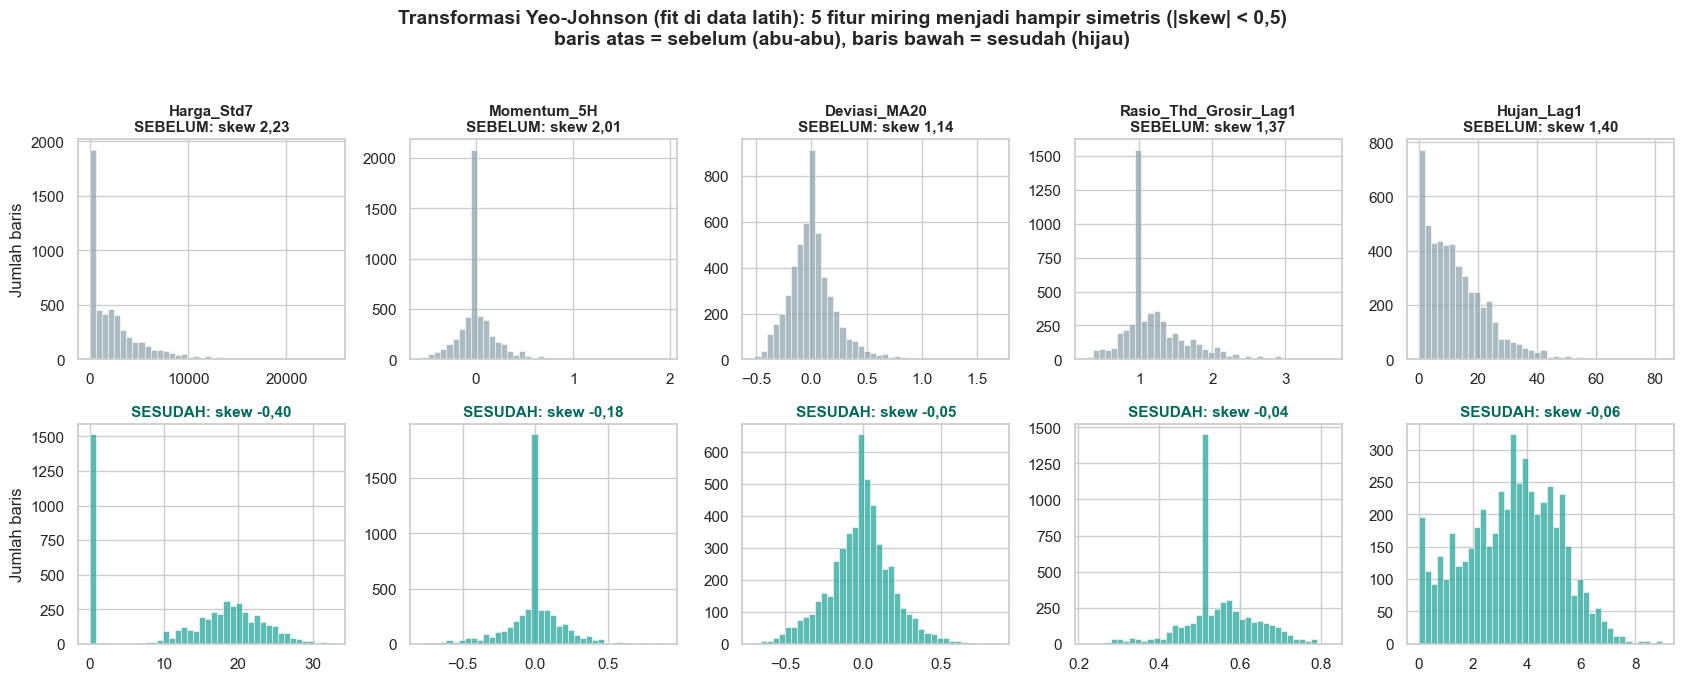

In [8]:
META = ["Tanggal", "Kategori_Pasar"]
BINER = ["Is_Imputasi", "Is_Ramadan", "Is_Menjelang_Hari_Besar", "Is_Musim_Hujan"] + ohe_cols
ORDINAL = ["Level_Rantai_Pasok", "Kategori_Cuaca_Lag1", "Kategori_Hujan_Lag1", "Kategori_Suhu_Lag1", "Bulan", "Hari_dalam_Minggu"]
FITUR_HARGA = ["Harga_Cabai_Merah_Agregat", "Harga_Lag1", "Harga_Lag5", "Harga_Lag20", "Harga_MA7", "Harga_MA20",
               "Harga_Produsen_Lag1", "Harga_PB_Lag1", "Interaksi_Lag1_x_MusimHujan", "TE_Pasar_Bulan"]
KONTINU = [c for c in train.columns if c not in META + [TARGET] + BINER + ORDINAL]
skew_before = train[KONTINU].skew().sort_values(ascending=False)
transform_cols = [c for c in KONTINU if abs(skew_before[c]) > 1 and c not in FITUR_HARGA]
print("Fitur kontinu:", len(KONTINU))
print("Ditransformasi Yeo-Johnson (|skew| > 1 dan bukan fitur harga):", transform_cols)
pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(train[transform_cols])
train_before = train[transform_cols].copy()
train[transform_cols] = pt.transform(train[transform_cols]); test[transform_cols] = pt.transform(test[transform_cols])
skew_tab = pd.DataFrame({"skew sebelum": train_before.skew(), "skew sesudah": train[transform_cols].skew(), "lambda": pt.lambdas_}).round(3)
display(skew_tab)

fig, axes = plt.subplots(2, len(transform_cols), figsize=(3.4 * len(transform_cols), 6.6))
for i, c in enumerate(transform_cols):
    sns.histplot(train_before[c], bins=40, ax=axes[0, i], color="#90a4ae"); axes[0, i].set_title(f"{c}\nSEBELUM: skew {skew_tab.loc[c,'skew sebelum']:.2f}".replace(".", ","), fontsize=11)
    sns.histplot(train[c], bins=40, ax=axes[1, i], color="#26a69a"); axes[1, i].set_title(f"SESUDAH: skew {skew_tab.loc[c,'skew sesudah']:.2f}".replace(".", ","), fontsize=11, color="#00695c")
    axes[0, i].set_xlabel(""); axes[1, i].set_xlabel(""); axes[0, i].set_ylabel("Jumlah baris" if i == 0 else ""); axes[1, i].set_ylabel("Jumlah baris" if i == 0 else "")
fig.suptitle("Transformasi Yeo-Johnson (fit di data latih): 5 fitur miring menjadi hampir simetris (|skew| < 0,5)\nbaris atas = sebelum (abu-abu), baris bawah = sesudah (hijau)", y=1.03, fontweight="bold", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "03_transformasi_skewness.png"); plt.show()

**Apa:** transformasi **Yeo-Johnson** (fit di train) untuk 5 fitur kontinu dengan |skew| > 1:

| Fitur | Skew sebelum | Skew sesudah |
|---|---|---|
| Harga_Std7 | 2,23 | −0,40 |
| Momentum_5H | 2,01 | −0,18 |
| Deviasi_MA20 | 1,14 | −0,05 |
| Rasio_Thd_Grosir_Lag1 | 1,37 | −0,04 |
| Hujan_Lag1 | 1,40 | −0,06 |

**Mengapa:**
- Dipakai Yeo-Johnson, bukan log, karena Momentum dan Deviasi bisa bernilai negatif dan hujan bisa 0.
- Fitur harga (lag/MA/hulu/TE) **sengaja tidak ditransformasi**. Hubungannya dengan target hampir linear dalam satuan Rupiah
  (rho Lag1 = 0,98), dan mentransformasinya akan merusak hubungan itu.

**Arti:** kelima fitur menjadi hampir simetris (|skew| < 0,5), sehingga titik ekstrem tidak lagi mendominasi koefisien
model linear.

**Pengaruh:** kolom yang sama ditransformasi di test memakai lambda dari train.

## 6 · Scaling

In [9]:
scale_cols = KONTINU + ["Bulan", "Hari_dalam_Minggu", "Level_Rantai_Pasok", "Kategori_Cuaca_Lag1", "Kategori_Hujan_Lag1", "Kategori_Suhu_Lag1"]
scaler = StandardScaler().fit(train[scale_cols])
train_unscaled, test_unscaled = train.copy(), test.copy()
train[scale_cols] = scaler.transform(train[scale_cols]); test[scale_cols] = scaler.transform(test[scale_cols])
cek = pd.DataFrame({"mean train": train[scale_cols].mean(), "std train": train[scale_cols].std(ddof=0),
                    "mean test": test[scale_cols].mean(), "std test": test[scale_cols].std(ddof=0)}).round(3)
print(f"Kolom di-scale: {len(scale_cols)} | biner/one-hot tidak di-scale: {BINER}")
cek.head(8)

Kolom di-scale: 30 | biner/one-hot tidak di-scale: ['Is_Imputasi', 'Is_Ramadan', 'Is_Menjelang_Hari_Besar', 'Is_Musim_Hujan', 'Pasar_Pedagang_Besar', 'Pasar_Pasar_Tradisional', 'Pasar_Pasar_Modern']


,mean train,std train,mean test,std test
Harga_Cabai_Merah_Agregat,-0.0,1.0,0.483,1.085
Bulan_sin,0.0,1.0,0.060,0.975
Bulan_cos,-0.0,1.0,0.114,1.020
Harga_Lag1,-0.0,1.0,0.429,1.126
Harga_Lag5,0.0,1.0,0.432,1.127
Harga_Lag20,0.0,1.0,0.396,1.143
Harga_MA7,0.0,1.0,0.441,1.121
Harga_MA20,0.0,1.0,0.448,1.105


**Apa:** `StandardScaler` (z-score) di-fit pada train untuk 30 kolom numerik/ordinal. Kolom biner dan one-hot tidak di-scale.

**Mengapa:** Lasso, RFE dengan regresi linear, dan VIF di Tahap 4–5 sensitif terhadap satuan. Tanpa scaling, harga (puluhan
ribu) akan "mengalahkan" suhu (puluhan). Dipilih StandardScaler, bukan MinMax, karena outlier harga yang legit akan menekan
skala MinMax.

**Arti:** train memiliki mean 0 dan std 1. Mean test untuk fitur harga sekitar +0,43, artinya **harga 2025 rata-rata sekitar
0,43 std di atas periode latih** (ada lonjakan Sep–Nov 2025). Ini wajar dan menjadi bukti bahwa scaler tidak "mengintip"
data uji.

**Pengaruh:** disimpan dua versi, `03_train_fe.csv` (scaled) dan `03_train_fe_unscaled.csv` (untuk interpretasi korelasi
di Tahap 5).

## 7 · Bukti kegunaan fitur baru

In [10]:
tr_trad = train_unscaled[train_unscaled["Kategori_Pasar"] == "Pasar Tradisional"]
pembanding = [
    ("Harga_Lag1", "(tanpa fitur lag, model hanya punya Bulan)", "Bulan"),
    ("Harga_MA7", "Bulan", "Bulan"),
    ("TE_Pasar_Bulan", "Bulan", "Bulan"),
    ("Harga_PB_Lag1", "Level_Rantai_Pasok", "Level_Rantai_Pasok"),
    ("Akumulasi_Hujan_60H_Lag11Mgg", "Curah hujan hari-H (kolom asal)", None),
    ("Akumulasi_Hujan_30H", "Curah hujan hari-H (kolom asal)", None),
    ("Hari_Hujan_Lebat_30H", "Curah hujan hari-H (kolom asal)", None),
]
asal_hujan = df.merge(cuaca[["Curah_Hujan_mm"]], left_on="Tanggal", right_index=True)
asal_hujan = asal_hujan[asal_hujan["Tanggal"] < TGL_SPLIT].set_index(["Tanggal", "Kategori_Pasar"])["Curah_Hujan_mm"]
tr_idx = train_unscaled.set_index(["Tanggal", "Kategori_Pasar"])
rows = []
for baru, label_asal, asal in pembanding:
    r_baru = tr_idx[baru].corr(tr_idx[TARGET], method="spearman")
    r_asal = (tr_idx[asal] if asal else asal_hujan.reindex(tr_idx.index)).corr(tr_idx[TARGET], method="spearman")
    rows.append({"fitur baru": baru, "kolom asal pembanding": label_asal if asal is None else asal,
                 "|rho| fitur baru": abs(round(r_baru, 3)), "|rho| kolom asal": abs(round(r_asal, 3))})
bukti_kor = pd.DataFrame(rows)
bukti_kor["peningkatan"] = (bukti_kor["|rho| fitur baru"] - bukti_kor["|rho| kolom asal"]).round(3)
print("Korelasi Spearman dengan target (data latih, semua pasar):")
display(bukti_kor)

flag_rows = []
for f in ["Is_Musim_Hujan", "Is_Ramadan", "Is_Menjelang_Hari_Besar"]:
    m1 = tr_trad.loc[tr_trad[f] == 1, TARGET].mean(); m0 = tr_trad.loc[tr_trad[f] == 0, TARGET].mean()
    flag_rows.append({"flag": f, "rata2 harga saat 1 (Rp)": round(m1), "rata2 harga saat 0 (Rp)": round(m0),
                      "selisih (%)": round((m1 / m0 - 1) * 100, 1), "n (flag=1)": int((tr_trad[f] == 1).sum())})
bukti_flag = pd.DataFrame(flag_rows)
print("Perbedaan rata-rata harga Pasar Tradisional (train) menurut flag:")
display(bukti_flag)

Korelasi Spearman dengan target (data latih, semua pasar):


,fitur baru,kolom asal pembanding,|rho| fitur baru,|rho| kolom asal,peningkatan
0,Harga_Lag1,Bulan,0.980,0.017,0.963
1,Harga_MA7,Bulan,0.944,0.017,0.927
2,TE_Pasar_Bulan,Bulan,0.602,0.017,0.585
3,Harga_PB_Lag1,Level_Rantai_Pasok,0.657,0.580,0.077
4,Akumulasi_Hujan_60H_Lag11Mgg,Curah hujan hari-H (kolom asal),0.220,0.049,0.171
5,Akumulasi_Hujan_30H,Curah hujan hari-H (kolom asal),0.135,0.049,0.086
6,Hari_Hujan_Lebat_30H,Curah hujan hari-H (kolom asal),0.177,0.049,0.128


Perbedaan rata-rata harga Pasar Tradisional (train) menurut flag:


,flag,rata2 harga saat 1 (Rp),rata2 harga saat 0 (Rp),selisih (%),n (flag=1)
0,Is_Musim_Hujan,35510,36875,-3.7,436
1,Is_Ramadan,31176,36887,-15.5,107
2,Is_Menjelang_Hari_Besar,37690,36267,3.9,131


**Apa:** bukti kegunaan fitur baru. Korelasi Spearman fitur baru dibandingkan dengan kolom asal pembandingnya (data latih),
ditambah selisih rata-rata harga untuk fitur flag.

**Arti:**
- `Harga_Lag1` |rho| = **0,980** dan `Harga_MA7` 0,944, sedangkan `Bulan` hanya 0,017. Fitur lag adalah kunci prediksi.
- `Harga_PB_Lag1` 0,657 vs `Level_Rantai_Pasok` 0,580. Harga grosir kemarin menambah informasi di atas posisi rantai pasok.
- Fitur hujan rekayasa **2–4× lebih kuat** daripada hujan hari-H (0,049): `Akumulasi_Hujan_60H_Lag11Mgg` 0,220,
  `Hari_Hujan_Lebat_30H` 0,177, `Akumulasi_Hujan_30H` 0,135.
- Flag di Pasar Tradisional (train):
  - `Is_Ramadan`: harga **15,5% lebih rendah**, konsisten dengan temuan EDA bahwa harga turun menjelang Lebaran.
  - `Is_Menjelang_Hari_Besar`: +3,9%.
  - `Is_Musim_Hujan`: **−3,7%**. Arahnya berbeda dengan crosstab EDA (yang mencakup 2025) karena lonjakan terbesar di
    periode latih terjadi pada Jun–Sep 2022, di luar Sep–Des.

**Pengaruh:** temuan `Is_Musim_Hujan` dilaporkan apa adanya. Flag ini tidak dibuang secara manual, melainkan diserahkan ke
seleksi fitur objektif di Tahap 4.

In [11]:
fitur_model = [c for c in train.columns if c not in META + [TARGET]]
KOLOM_ASAL = ["Harga_Cabai_Merah_Agregat", "Is_Imputasi"]      # dibawa dari 01_clean.csv, BUKAN hasil feature engineering
FITUR_FE = [c for c in fitur_model if c not in KOLOM_ASAL]       # fitur hasil feature engineering
KELOMPOK = {
    "1. Waktu & siklik": ["Bulan", "Hari_dalam_Minggu", "Bulan_sin", "Bulan_cos"],
    "2. Lag harga per pasar": ["Harga_Lag1", "Harga_Lag5", "Harga_Lag20"],
    "3. Agregasi bergulir per pasar": ["Harga_MA7", "Harga_MA20", "Harga_Std7"],
    "4. Rasio / selisih": ["Momentum_5H", "Deviasi_MA20", "Rasio_Thd_Grosir_Lag1"],
    "5. Antar-kelompok (harga pasar hulu)": ["Harga_Produsen_Lag1", "Harga_PB_Lag1"],
    "6. Domain cuaca (H-1)": ["Hujan_Lag1", "Akumulasi_Hujan_7H", "Akumulasi_Hujan_30H", "Akumulasi_Hujan_60H_Lag11Mgg",
                              "Hari_Hujan_Lebat_30H", "Suhu_Lag1", "Angin_Lag1", "Kategori_Cuaca_Lag1"],
    "7. Kalender & flag": ["Hari_Menuju_Idul_Fitri", "Is_Ramadan", "Is_Menjelang_Hari_Besar", "Is_Musim_Hujan"],
    "8. Interaksi": ["Interaksi_Lag1_x_MusimHujan"],
    "9. Diskretisasi": ["Kategori_Hujan_Lag1", "Kategori_Suhu_Lag1"],
    "10. Encoding Kategori_Pasar": ohe_cols + ["Level_Rantai_Pasok", "TE_Pasar_Bulan"],
}
ke_kelompok = {f: k for k, fs in KELOMPOK.items() for f in fs}

# --- PEMERIKSAAN KONSISTENSI: kamus fitur = daftar kelompok = kolom fitur di CSV ---
kamus_df = pd.DataFrame(kamus)
assert kamus_df["fitur"].is_unique, "ada fitur tercatat dua kali di kamus"
assert set(kamus_df["fitur"]) == set(FITUR_FE) == set(ke_kelompok), (
    set(kamus_df["fitur"]) ^ set(FITUR_FE), set(ke_kelompok) ^ set(FITUR_FE))
kamus_df = kamus_df.set_index("fitur").loc[FITUR_FE].reset_index()      # urut sesuai kolom CSV
kamus_df.insert(1, "kelompok", kamus_df["fitur"].map(ke_kelompok))
kamus_df.insert(0, "no", range(1, len(kamus_df) + 1))

kolom_csv = META + [TARGET] + fitur_model
komposisi = pd.DataFrame([
    {"bagian": "Identitas & target", "jumlah kolom": len(META) + 1, "kolom": ", ".join(META + [TARGET])},
    {"bagian": "Kolom asal dari 01_clean.csv (bukan fitur baru; diuji di Tahap 4)", "jumlah kolom": len(KOLOM_ASAL), "kolom": ", ".join(KOLOM_ASAL)},
    {"bagian": "Fitur hasil feature engineering", "jumlah kolom": len(FITUR_FE), "kolom": "rincian 10 kelompok di tabel berikut"},
])
komposisi.loc[len(komposisi)] = {"bagian": "TOTAL kolom 03_train_fe.csv / 03_test_fe.csv", "jumlah kolom": int(komposisi["jumlah kolom"].sum()), "kolom": ""}
assert komposisi["jumlah kolom"].iloc[-1] == len(kolom_csv) == train[kolom_csv].shape[1] == test[kolom_csv].shape[1]

per_kelompok = (kamus_df.assign(kelompok=pd.Categorical(kamus_df["kelompok"], categories=list(KELOMPOK), ordered=True))
                .groupby("kelompok", observed=True).agg(jumlah=("fitur", "size"), fitur=("fitur", ", ".join)))
per_kelompok.loc["TOTAL"] = [int(per_kelompok["jumlah"].sum()), ""]
assert per_kelompok.loc["TOTAL", "jumlah"] == len(FITUR_FE)
print("KOMPOSISI KOLOM CSV hasil Tahap 3:")
display(komposisi)
print(f"RINCIAN {len(FITUR_FE)} FITUR HASIL FEATURE ENGINEERING per kelompok:")
display(per_kelompok)

train[kolom_csv].to_csv(PROC / "03_train_fe.csv", index=False)
test[kolom_csv].to_csv(PROC / "03_test_fe.csv", index=False)
train_unscaled[kolom_csv].to_csv(PROC / "03_train_fe_unscaled.csv", index=False)
kamus_df.to_csv(PROC / "03_kamus_fitur.csv", index=False)

ringkasan = {
    "baris_setelah_fe": int(len(df)), "baris_dibuang_riwayat": int(na_awal.sum()),
    "train_baris": int(len(train)), "test_baris": int(len(test)),
    "train_periode": [f"{train['Tanggal'].min():%Y-%m-%d}", f"{train['Tanggal'].max():%Y-%m-%d}"],
    "test_periode": [f"{test['Tanggal'].min():%Y-%m-%d}", f"{test['Tanggal'].max():%Y-%m-%d}"],
    "jumlah_kolom_csv": len(kolom_csv), "jumlah_kolom_fitur": len(fitur_model),
    "jumlah_fitur_hasil_fe": len(FITUR_FE), "kolom_asal_bukan_fe": KOLOM_ASAL,
    "jumlah_kelompok_fitur": len(KELOMPOK), "fitur_per_kelompok": {k: len(v) for k, v in KELOMPOK.items()},
    "transformasi": skew_tab.to_dict(orient="index"), "batas_suhu": [round(float(b), 2) for b in batas_suhu[1:-1]],
    "bukti_korelasi": bukti_kor.to_dict(orient="records"), "bukti_flag": bukti_flag.to_dict(orient="records"),
    "fitur_hasil_fe": FITUR_FE, "fitur_model": fitur_model,
}
(PROC / "03_ringkasan.json").write_text(json.dumps(ringkasan, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print(f"03_train_fe.csv: {len(kolom_csv)} kolom = {len(META) + 1} identitas/target + {len(KOLOM_ASAL)} kolom asal + "
      f"{len(FITUR_FE)} fitur hasil feature engineering")
print("Train:", train[kolom_csv].shape, "| Test:", test[kolom_csv].shape, "| kamus fitur:", kamus_df.shape[0], "baris")

KOMPOSISI KOLOM CSV hasil Tahap 3:


,bagian,jumlah kolom,kolom
0,Identitas & target,3,"Tanggal, Kategori_Pasar, Harga_Cabai_Merah_Ker..."
1,Kolom asal dari 01_clean.csv (bukan fitur baru...,2,"Harga_Cabai_Merah_Agregat, Is_Imputasi"
2,Fitur hasil feature engineering,35,rincian 10 kelompok di tabel berikut
3,TOTAL kolom 03_train_fe.csv / 03_test_fe.csv,40,


RINCIAN 35 FITUR HASIL FEATURE ENGINEERING per kelompok:


,jumlah,fitur
kelompok,,
1. Waktu & siklik,4,"Bulan, Hari_dalam_Minggu, Bulan_sin, Bulan_cos"
2. Lag harga per pasar,3,"Harga_Lag1, Harga_Lag5, Harga_Lag20"
3. Agregasi bergulir per pasar,3,"Harga_MA7, Harga_MA20, Harga_Std7"
4. Rasio / selisih,3,"Momentum_5H, Deviasi_MA20, Rasio_Thd_Grosir_Lag1"
5. Antar-kelompok (harga pasar hulu),2,"Harga_Produsen_Lag1, Harga_PB_Lag1"
6. Domain cuaca (H-1),8,"Hujan_Lag1, Akumulasi_Hujan_7H, Akumulasi_Huja..."
7. Kalender & flag,4,"Hari_Menuju_Idul_Fitri, Is_Ramadan, Is_Menjela..."
8. Interaksi,1,Interaksi_Lag1_x_MusimHujan
9. Diskretisasi,2,"Kategori_Hujan_Lag1, Kategori_Suhu_Lag1"


03_train_fe.csv: 40 kolom = 3 identitas/target + 2 kolom asal + 35 fitur hasil feature engineering
Train: (5144, 40) | Test: (1128, 40) | kamus fitur: 35 baris


**Komposisi kolom file hasil Tahap 3** (diverifikasi otomatis oleh `assert` di sel atas):

| Bagian | Jumlah kolom | Kolom |
|---|---|---|
| Identitas & target | 3 | `Tanggal`, `Kategori_Pasar`, `Harga_Cabai_Merah_Keriting` |
| Kolom asal dari `01_clean.csv` (bukan fitur baru) | 2 | `Harga_Cabai_Merah_Agregat` (kandidat leakage), `Is_Imputasi` (penanda kualitas) |
| **Fitur hasil feature engineering** | **35** | rincian di bawah |
| **Total kolom `03_train_fe.csv` / `03_test_fe.csv`** | **40** | |

| Kelompok | Jumlah | Fitur |
|---|---|---|
| 1. Waktu & siklik | 4 | Bulan, Hari_dalam_Minggu, Bulan_sin, Bulan_cos |
| 2. Lag harga per pasar | 3 | Harga_Lag1, Harga_Lag5, Harga_Lag20 |
| 3. Agregasi bergulir per pasar | 3 | Harga_MA7, Harga_MA20, Harga_Std7 |
| 4. Rasio / selisih | 3 | Momentum_5H, Deviasi_MA20, Rasio_Thd_Grosir_Lag1 |
| 5. Antar-kelompok (harga pasar hulu) | 2 | Harga_Produsen_Lag1, Harga_PB_Lag1 |
| 6. Domain cuaca (H-1) | 8 | Hujan_Lag1, Akumulasi_Hujan_7H, Akumulasi_Hujan_30H, Akumulasi_Hujan_60H_Lag11Mgg, Hari_Hujan_Lebat_30H, Suhu_Lag1, Angin_Lag1, Kategori_Cuaca_Lag1 |
| 7. Kalender & flag | 4 | Hari_Menuju_Idul_Fitri, Is_Ramadan, Is_Menjelang_Hari_Besar, Is_Musim_Hujan |
| 8. Interaksi | 1 | Interaksi_Lag1_x_MusimHujan |
| 9. Diskretisasi | 2 | Kategori_Hujan_Lag1 (ambang BMKG), Kategori_Suhu_Lag1 (3 kuantil train) |
| 10. Encoding `Kategori_Pasar` | 5 | Pasar_Pedagang_Besar, Pasar_Pasar_Tradisional, Pasar_Pasar_Modern (one-hot), Level_Rantai_Pasok (ordinal), TE_Pasar_Bulan (target encoding) |
| **Total** | **35** | |

> **Koreksi dari versi sebelumnya:** versi lama menyebut "31 fitur hasil rekayasa" karena 3 kolom one-hot dan
> `Level_Rantai_Pasok` tidak ikut dihitung. Padahal keempatnya adalah kolom baru di CSV yang ikut diseleksi di Tahap 4.
> Jumlah yang benar dan konsisten dengan CSV adalah **35 fitur hasil feature engineering**. Angka 35 ini juga yang
> menjadi "35 kandidat" di Tahap 4 (37 kolom fitur − `Harga_Cabai_Merah_Agregat` − `Is_Imputasi`).
> File `03_kamus_fitur.csv` kini berisi tepat 35 baris, satu baris per kolom fitur.

## Ringkasan Tahap 3
| Item | Nilai |
|---|---|
| Baris sebelum → sesudah | 6.352 → 6.272 (80 baris tanpa riwayat lag dibuang) |
| Train / Test | 5.144 (2020-01-28 s.d. 2024-12-31) / 1.128 (2025-01-01 s.d. 2026-01-29) |
| Kolom CSV `03_train_fe.csv` | **40** = 3 identitas/target + 2 kolom asal (`Harga_Cabai_Merah_Agregat`, `Is_Imputasi`) + **35 fitur hasil feature engineering** |
| Fitur hasil feature engineering | **35 fitur dari 10 kelompok**: waktu/siklik 4, lag 3, agregasi bergulir 3, rasio 3, antar-kelompok 2, cuaca 8, kalender/flag 4, interaksi 1, diskretisasi 2, encoding 5 |
| Kamus fitur | `03_kamus_fitur.csv`: 35 baris (1 baris per kolom fitur) berisi kelompok, jenis, rumus, dan makna bisnis |
| Transformasi | Yeo-Johnson pada 5 fitur (skew 1,14–2,23 → −0,40 s.d. −0,04) |
| Scaling | StandardScaler pada 30 kolom (fit train saja) |

> **Catatan leakage:** `Harga_Cabai_Merah_Agregat` (harga baris "Cabai Merah" di hari yang sama) **sengaja diteruskan**
> sebagai kandidat yang akan diuji pada pemeriksaan leakage di Tahap 4. Kolom ini bukan fitur rekayasa.